# Modele préféré des archivistes

Comme il s'agit d'une évaluation faite par plusieurs archivistes (les memes) sur plusieurs textes (les memes) et qu'il peut y avoir des trous dans les données, on doit utiliser un modele qui est un **mixed effect model** pour savoir quel est le modele effectivement préféré par les archivistes.

In [1]:
import numpy as np
import pandas as pd
import statsmodels as sm
import statsmodels.formula.api as smf
import sqlite3

In [2]:
## Récupère les vraies données depuis la db
db = "../model_ranking/backend/databases/RESULTS.db"
with sqlite3.connect(db) as conn:
    ranking = pd.read_sql(
        """
        SELECT r.id, m.alias, r.usrname, r.ranking
        FROM ranking r JOIN models m ON r.model = m.name""",
        conn)
ranking

,id,alias,usrname,ranking
0,0,brabant_xvii_ner,Rolande,4
1,0,vieille_france_v2,Rolande,3
2,0,vieille_france,Rolande,2
3,0,mistralnemo,Rolande,3
4,0,mistral7b,Rolande,3
...,...,...,...,...
1539,220,vieille_france,Rolande,1
1540,220,mistralnemo,Rolande,2
1541,220,mistral7b,Rolande,2
1542,220,llama,Rolande,1


In [3]:
# Concretement, ca signifie qu'on a 
print(f"Total number of evaluations {len(ranking)}")
print()
ranking[["usrname", "id"]].groupby(by='usrname').count().rename(columns={"id": "nb evals"})

Total number of evaluations 1544



,nb evals
usrname,
Annelies,7
Klaas,21
Rolande,1516


In [4]:
### Comme on n'a pas de vraies donnéees (du moins pas ici), je vais en simuler
#usrnames   = pd.Series([ "rolande", "klaas", "gert", "annelies", "raphaelle" ])
#with sqlite3.connect(db) as conn:
#    modelnames = pd.read_sql("select alias from models", conn)
#
### on compte 300 data points
#nb_points = 300
##
#docs     = np.random.randint(0, high=420, size=(nb_points,))
#models   = modelnames['alias'].iloc[np.random.randint(0, high=len(modelnames), size=(nb_points,))]
#usrs     = usrnames.iloc[np.random.randint(0, high=len(usrnames), size=(nb_points,))]
#rankings = np.random.randint(0, high=6, size=(nb_points,))
#
#ranking  = pd.DataFrame(np.stack([docs, models, usrs, rankings], axis=1), columns=["id", "alias", "usrname", "ranking"])
#ranking

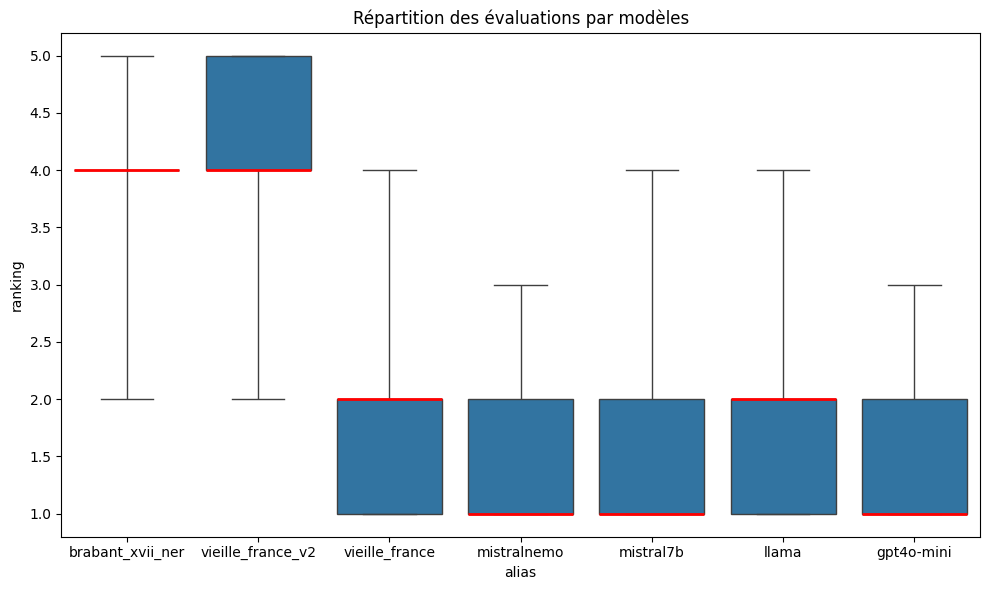

In [6]:
## Visualisation exploratoire des données
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(10, 6))
plt.title("Répartition des évaluations par modèles")

ranking['id'] = ranking['id'].astype(np.int16)
ranking['ranking'] = ranking['ranking'].astype(np.int8)

sns.boxplot(x='alias', y='ranking', data=ranking, whis=(0, 100), medianprops={"color": "r", "linewidth": 2},)

plt.tight_layout()
plt.savefig("ranking_per_model.png")
plt.show()

In [7]:
## conversion des do catégoriques en attr numériques
ranking["usrname"] = ranking["usrname"].astype("category")
ranking["alias"]   = ranking["alias"].astype("category")
ranking["id"]      = ranking["id"].astype("category")
ranking["ranking"] = ranking["ranking"].astype(np.float32)
ranking = ranking.rename(columns={"id": "document"})
ranking.dtypes

document    category
alias       category
usrname     category
ranking      float32
dtype: object

In [8]:
## on appplique le modele pour de vrai
# 1. La formule principale ne contient que les effets fixes
formula = "ranking ~ alias"

# 2. On définit les effets aléatoires dans un dictionnaire
# C'est la manière explicite de demander des intercepts aléatoires
vc_formula = {
    "document": "0 + C(document)",
    "usrname": "0 + C(usrname)"
}

model = smf.mixedlm(
    formula=formula,
    vc_formula=vc_formula,
    data=ranking,
    groups=ranking["document"])
results = model.fit()

## Comment comprendre le résultat

Le résulat de notre summary, il faut regarder la valeur de nos intercepts. 
Le modele se base par rapport à un model de reference (qui n'est pas affiché). 
Les lignes suivantes, donnent la différence par rapport à l'intercept de la référence. 
Si c'est positif, ca veut dire que l'effet qu'on cherche à prédire est meilleur que la réf.
Si c'est négatif, ca veut dire que l'effet qu'on cherche à montrer est moins bon que la réf;

**ATTENTION**
Pour pouvoir dire qu'un modele est vraiment meilleur que l'autre, on doit aussi regarder la valeur dans la colonne `P>|z|`.
Si cette valeur est > 0.05 ca veut dire que la différence n'est pas statistiquement significative.
Si cette valeur est < 0.05 ca veut dire qu'il y a vraiment un truc.

In [9]:
results.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                Mixed Linear Model Regression Results
======================================================================
Model:                  MixedLM     Dependent Variable:     ranking   
No. Observations:       1544        Method:                 REML      
No. Groups:             220         Scale:                  0.3702    
Min. group size:        3           Log-Likelihood:         -1518.2317
Max. group size:        21          Converged:              Yes       
Mean group size:        7.0                                           
----------------------------------------------------------------------
                           Coef.  Std.Err.    z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                   4.035    0.044  91.459 0.000  3.948  4.121
alias[T.gpt4o-mini]        -2.627    0.058 -45.357 0.000 -2.741 -2.513
alias[T.llama]             -2.203    0.058 -38.135 0.000 -2.317 -2.090
alias[T.mistral7b]         -2.707    0.058 -46.624 0.000 -2.821 -2.593
alias[T.mistralnemo]       -2.544    0.058 -43.820 0.000 -2.658 -2.430
alias[T.vieille_france]    -2.186    0.058 -37.835 0.000 -2.299 -2.073
alias[T.vieille_france_v2]  0.223    0.058   3.842 0.000  0.109  0.337
document Var                0.044    0.042                            
usrname Var                 0.015    0.042                            
======================================================================

"""

**Conclusion:** 
Ici on voit que vieille_france_v2 est meilleur que les autres (suivi par brabant_ner ).
On voit aussi que la variabilité entre les documents est relativement faible. Ce qui signifie qu'il n'y a pas vraiment de document plus difficile que les autres.
On voit encore que la variabilité entre les usrnames (évaluateurs) est à nouveau relativement faible (de l'odre de 0.04 / 5). Il y a donc un accord assez fort entre les différents évaluateurs qui ont pris part à l'étude.

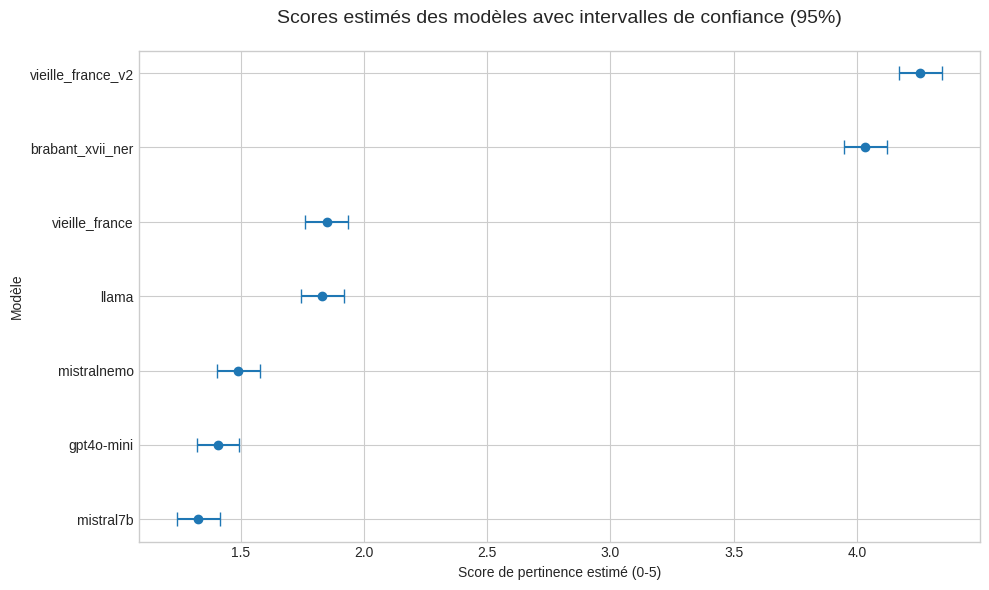

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Supposons que 'results' est l'objet contenant les résultats de votre modèle
# et 'ranking' est votre DataFrame de données original.

### Étape 1: Extraire les coefficients et les intervalles de confiance
##params = results.params
##conf = results.conf_int()
# Étape 1: Extraire UNIQUEMENT les coefficients des effets fixes
# On sélectionne seulement les lignes qui concernent l'Intercept ou un alias
params = results.params[results.params.index.str.contains('Intercept|alias')]
conf = results.conf_int()[results.conf_int().index.str.contains('Intercept|alias')]


# Créer un DataFrame pour la visualisation
plot_data = pd.DataFrame({
    'coef': params,
    'ci_lower': conf[0],
    'ci_upper': conf[1]
})

# Isoler le nom du modèle de référence (l'Intercept)
# (C'est le premier modèle par ordre alphabétique qui n'est pas dans l'index)
ref_model_name = sorted(list(ranking['alias'].unique()))[0]
intercept_val = plot_data.loc['Intercept', 'coef']
intercept_ci = plot_data.loc['Intercept', ['ci_lower', 'ci_upper']]

# Calculer les scores réels et les CI pour chaque modèle
# (en ajoutant la valeur de l'intercept aux coefficients)
plot_data = plot_data.drop('Intercept')
plot_data['score_estime'] = intercept_val + plot_data['coef']
plot_data['ci_lower'] = intercept_ci['ci_lower'] + plot_data['coef']
plot_data['ci_upper'] = intercept_ci['ci_upper'] + plot_data['coef']

# Ajouter le modèle de référence
ref_df = pd.DataFrame({
    'score_estime': [intercept_val],
    'ci_lower': [intercept_ci['ci_lower']],
    'ci_upper': [intercept_ci['ci_upper']]
}, index=[f"{ref_model_name}"])
plot_data = pd.concat([plot_data, ref_df])

# Nettoyer les noms des modèles
plot_data.index = plot_data.index.str.replace('alias[T.', '', regex=False).str.replace(']', '', regex=False)
plot_data = plot_data.sort_values('score_estime', ascending=False)


# Étape 2: Créer le graphique
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

# Erreurs à afficher (distance entre le point et la barre de CI)
errors = [plot_data['score_estime'] - plot_data['ci_lower'], 
          plot_data['ci_upper'] - plot_data['score_estime']]

ax.errorbar(x=plot_data['score_estime'], y=plot_data.index, xerr=errors,
            fmt='o', # 'o' pour les points
            linestyle='None', # Pas de ligne reliant les points
            capsize=5, # Taille des "chapeaux" des barres d'erreur
            label='Score estimé & IC 95%')

ax.set_title("Scores estimés des modèles avec intervalles de confiance (95%)", fontsize=14, pad=20)
ax.set_xlabel("Score de pertinence estimé (0-5)")
ax.set_ylabel("Modèle")
ax.invert_yaxis() # Affiche le meilleur modèle en haut
plt.tight_layout()
plt.savefig("dot_plot.png")
plt.show()
